# Colorectal Cancer Data Cleaning and Exploration

This notebook cleans the colorectal cancer dataset and runs three statistical tests, each with a plot.

**Dataset source:** [Colorectal Cancer Global Dataset & Predictions (Kaggle)](https://www.kaggle.com/datasets/ankushpanday2/colorectal-cancer-global-dataset-and-predictions)

# Section 1: Data Preprocessing and Data Cleaning

This section imports the CSV into a pandas DataFrame, removes extra whitespace, checks numeric values, handles duplicates and missing values, and converts data types.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from itertools import combinations
from scipy import stats

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

## 1.1 Import and inspect the raw data

`skipinitialspace=True` removes spaces immediately following commas. The next cleaning step also strips trailing spaces from headers and text values.

In [2]:
data_path = "colorectal_cancer_dataset.csv"
raw_df = pd.read_csv(data_path, skipinitialspace=True)

print(f"Raw dataset: {raw_df.shape[0]:,} rows and {raw_df.shape[1]} columns")
display(raw_df.head())

# Check data types, missing values, and unique values before cleaning.
raw_profile = pd.DataFrame({
    "Data_Type": raw_df.dtypes.astype(str),
    "Missing_Count": raw_df.isna().sum(),
    "Missing_Rate": raw_df.isna().mean(),
    "Unique_Values": raw_df.nunique(dropna=False),
})
raw_profile

Raw dataset: 167,497 rows and 28 columns


,Patient_ID,Country,Age,Gender,Cancer_Stage,Tumor_Size_mm,Family_History,Smoking_History,Alcohol_Consumption,Obesity_BMI,Diet_Risk,Physical_Activity,Diabetes,Inflammatory_Bowel_Disease,Genetic_Mutation,Screening_History,Early_Detection,Treatment_Type,Survival_5_years,Mortality,Healthcare_Costs,Incidence_Rate_per_100K,Mortality_Rate_per_100K,Urban_or_Rural,Economic_Classification,Healthcare_Access,Insurance_Status,Survival_Prediction
0,1,UK,77,M,Localized,69,No,No,Yes,Overweight,Low,Low,No,No,No,Regular,Yes,Combination,Yes,No,54413,50,5,Urban,Developed,Moderate,Insured,Yes
1,2,UK,59,M,Localized,33,No,No,No,Overweight,Moderate,Low,No,No,No,Regular,No,Chemotherapy,Yes,No,76553,37,25,Urban,Developing,High,Uninsured,Yes
2,3,Japan,66,M,Regional,17,No,Yes,No,Normal,Low,Low,No,Yes,No,Irregular,No,Chemotherapy,Yes,No,62805,54,27,Urban,Developed,Moderate,Uninsured,No
3,4,USA,83,M,Regional,14,No,No,No,Obese,High,Low,No,No,No,Regular,No,Surgery,Yes,No,89393,45,11,Urban,Developed,Moderate,Insured,Yes
4,5,France,66,M,Localized,34,No,Yes,No,Normal,Low,Moderate,No,Yes,No,Never,Yes,Surgery,Yes,No,66425,15,27,Urban,Developing,High,Insured,Yes


,Data_Type,Missing_Count,Missing_Rate,Unique_Values
Patient_ID,int64,0,0.0,167497
Country,str,0,0.0,16
Age,int64,0,0.0,60
Gender,str,0,0.0,2
Cancer_Stage,str,0,0.0,3
Tumor_Size_mm,int64,0,0.0,75
Family_History,str,0,0.0,2
Smoking_History,str,0,0.0,2
Alcohol_Consumption,str,0,0.0,2
Obesity_BMI,str,0,0.0,3


## 1.2 Clean, validate, and transform

The main data-quality issue is padded whitespace in column names and categorical values. The code also checks required numeric ranges, removes duplicate rows and patient IDs, fills any missing values, converts Yes/No fields to binary integers, and stores repeated labels as categorical data. Rows where the mortality rate exceeds the incidence rate are flagged and retained because the CSV does not document the rates' time windows. changing them would require source clarification.

In [3]:
df = raw_df.copy()

# Standardize column names and categorical text.
df.columns = df.columns.str.strip()
text_columns = df.select_dtypes(include=["str", "object"]).columns
for column in text_columns:
    df[column] = df[column].str.strip()
df[text_columns] = df[text_columns].replace("", pd.NA)

# Parse numeric columns and replace impossible values with missing values.
numeric_columns = [
    "Patient_ID", "Age", "Tumor_Size_mm", "Healthcare_Costs",
    "Incidence_Rate_per_100K", "Mortality_Rate_per_100K"
]
for column in numeric_columns:
    df[column] = pd.to_numeric(df[column], errors="coerce")

valid_ranges = {
    "Age": (0, 120),
    "Tumor_Size_mm": (0, np.inf),
    "Healthcare_Costs": (0, np.inf),
    "Incidence_Rate_per_100K": (0, np.inf),
    "Mortality_Rate_per_100K": (0, np.inf),
}
invalid_numeric_values = 0
for column, (lower, upper) in valid_ranges.items():
    invalid = ~df[column].between(lower, upper, inclusive="both") & df[column].notna()
    invalid_numeric_values += int(invalid.sum())
    df.loc[invalid, column] = np.nan

# Count rows that may need source verification. Do not change them automatically.
rate_order_flags = int(
    (df["Mortality_Rate_per_100K"] > df["Incidence_Rate_per_100K"]).sum()
)

# Count and remove duplicate records. Patient_ID should uniquely identify a row.
exact_duplicates = int(df.duplicated().sum())
df = df.drop_duplicates().copy()
duplicate_patient_ids = int(df["Patient_ID"].duplicated().sum())
df = df.drop_duplicates(subset="Patient_ID", keep="first").copy()

# Patient_ID is required; remove rows where it is missing.
missing_patient_ids = int(df["Patient_ID"].isna().sum())
df = df.dropna(subset=["Patient_ID"]).copy()
df["Patient_ID"] = df["Patient_ID"].astype("int64")

missing_before_imputation = int(df.isna().sum().sum())
measurement_columns = [column for column in numeric_columns if column != "Patient_ID"]
for column in measurement_columns:
    df[column] = df[column].fillna(df[column].median())
df[measurement_columns] = df[measurement_columns].round().astype("int64")

text_columns = df.select_dtypes(include=["str", "object"]).columns
for column in text_columns:
    if df[column].isna().any():
        df[column] = df[column].fillna(df[column].mode().iloc[0])

# Convert Yes/No fields to 1/0 and remaining text fields to category dtype.
binary_columns = [
    "Family_History", "Smoking_History", "Alcohol_Consumption",
    "Diabetes", "Inflammatory_Bowel_Disease", "Genetic_Mutation",
    "Early_Detection", "Survival_5_years", "Mortality",
    "Survival_Prediction"
]
for column in binary_columns:
    df[column] = df[column].map({"No": 0, "Yes": 1}).astype("int8")

categorical_columns = df.select_dtypes(include=["str", "object"]).columns
for column in categorical_columns:
    df[column] = df[column].astype("category")

df = df.reset_index(drop=True)

In [4]:
quality_report = pd.Series({
    "Raw rows": len(raw_df),
    "Clean rows": len(df),
    "Exact duplicate rows found": exact_duplicates,
    "Duplicate patient IDs found": duplicate_patient_ids,
    "Missing patient IDs removed": missing_patient_ids,
    "Invalid numeric values found": invalid_numeric_values,
    "Rate-order flags retained for review": rate_order_flags,
    "Missing values before imputation": missing_before_imputation,
    "Missing values after cleaning": int(df.isna().sum().sum()),
})

display(quality_report.to_frame("Count"))
print(f"Patient IDs unique: {df['Patient_ID'].is_unique}")
print(f"Final dataset: {df.shape[0]:,} rows and {df.shape[1]} columns")
df.info()

,Count
Raw rows,167497
Clean rows,167497
Exact duplicate rows found,0
Duplicate patient IDs found,0
Missing patient IDs removed,0
Invalid numeric values found,0
Rate-order flags retained for review,25449
Missing values before imputation,0
Missing values after cleaning,0


Patient IDs unique: True
Final dataset: 167,497 rows and 28 columns
<class 'pandas.DataFrame'>
RangeIndex: 167497 entries, 0 to 167496
Data columns (total 28 columns):
 #   Column                      Non-Null Count   Dtype   
---  ------                      --------------   -----   
 0   Patient_ID                  167497 non-null  int64   
 1   Country                     167497 non-null  category
 2   Age                         167497 non-null  int64   
 3   Gender                      167497 non-null  category
 4   Cancer_Stage                167497 non-null  category
 5   Tumor_Size_mm               167497 non-null  int64   
 6   Family_History              167497 non-null  int8    
 7   Smoking_History             167497 non-null  int8    
 8   Alcohol_Consumption         167497 non-null  int8    
 9   Obesity_BMI                 167497 non-null  category
 10  Diet_Risk                   167497 non-null  category
 11  Physical_Activity           167497 non-null  category
 12  D

# Section 2: Basic Data Exploration and Summary Statistics

This section has three conclusions, and each one uses a different method: a chi-square test, a one-way ANOVA, and correlation tests. Each has one plot. Section 2.5 explains some problems with the data that affect how we read the results.

## 2.1 Dataset overview

One row represents one patient record, identified by `Patient_ID`. The cleaned dataset contains 167,497 entries and 28 columns. The CSV has no sampling or date fields, so the results describe these records only. `Survival_Prediction` looks like an output variable and could leak the answer if it were used to predict `Survival_5_years`.

In [5]:
print(f"Entries: {len(df):,}")
print(f"Columns: {df.shape[1]}")
print(f"Non-ID variables: {df.shape[1] - 1}")

summary_columns = [
    "Age", "Tumor_Size_mm", "Healthcare_Costs",
    "Incidence_Rate_per_100K", "Mortality_Rate_per_100K"
]
df[summary_columns].describe().round(2)

Entries: 167,497
Columns: 28
Non-ID variables: 27


,Age,Tumor_Size_mm,Healthcare_Costs,Incidence_Rate_per_100K,Mortality_Rate_per_100K
count,167497.00,167497.00,167497.00,167497.00,167497.00
mean,69.20,42.01,72452.17,34.53,17.02
std,11.87,21.67,27402.78,14.45,7.21
min,30.00,5.00,25000.00,10.00,5.00
25%,59.00,23.00,48760.00,22.00,11.00
50%,69.00,42.00,72344.00,35.00,17.00
75%,79.00,61.00,96227.00,47.00,23.00
max,89.00,79.00,119999.00,59.00,29.00


## 2.2 Conclusion 1: Early detection and five-year survival

**Method: chi-square test of independence**

- Null hypothesis: early detection and five-year survival are not related.
- Alternative hypothesis: early detection and five-year survival are related.
- Significance level: 0.05.

Both variables are yes/no categories, so a chi-square test fits. The test needs every expected count to be at least 5.

In [6]:
observed = pd.crosstab(df["Early_Detection"], df["Survival_5_years"])
observed.index = ["No early detection", "Early detection"]
observed.columns = ["Did not survive", "Survived"]

chi_square, p_value, degrees_of_freedom, expected = stats.chi2_contingency(observed, correction=False)
expected = pd.DataFrame(expected, index=observed.index, columns=observed.columns)

critical_value = stats.chi2.ppf(0.95, degrees_of_freedom)
survival_rates = observed["Survived"] / observed.sum(axis=1)

# Cramer's V shows how big the effect is. With this many rows, even a tiny gap can look significant.
cramers_v = np.sqrt(chi_square / observed.to_numpy().sum())

print("Observed counts:")
display(observed)
print("Expected counts if the two were not related:")
display(expected.round(2))
print(f"Smallest expected count: {expected.to_numpy().min():,.2f}")
print(f"Chi-square statistic: {chi_square:.3f}")
print(f"Critical value (0.05): {critical_value:.3f}")
print(f"p-value: {p_value:.4f}")
print(f"Cramer's V: {cramers_v:.4f}")
print("Reject the null hypothesis." if p_value < 0.05 else "Fail to reject the null hypothesis.")

Observed counts:


,Did not survive,Survived
No early detection,26880,40357
Early detection,40230,60030


Expected counts if the two were not related:


,Did not survive,Survived
No early detection,26939.44,40297.56
Early detection,40170.56,60089.44


Smallest expected count: 26,939.44
Chi-square statistic: 0.366
Critical value (0.05): 3.841
p-value: 0.5454
Cramer's V: 0.0015
Fail to reject the null hypothesis.


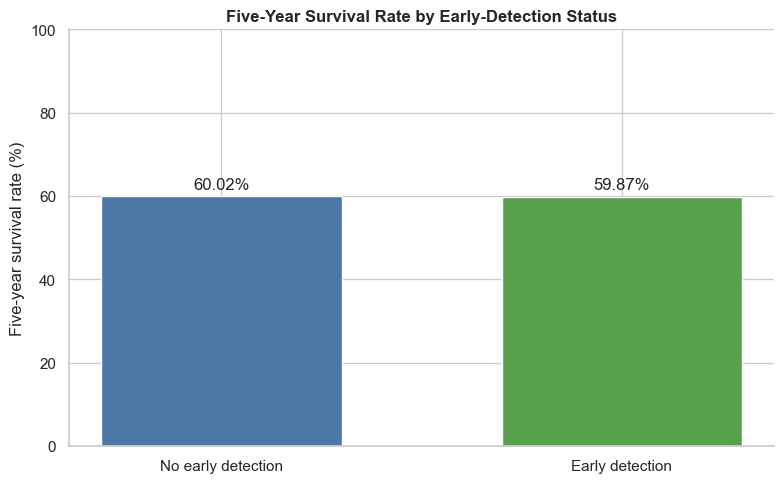

In [7]:
fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.bar(
    survival_rates.index,
    survival_rates * 100,
    color=["#4C78A8", "#59A14F"],
    width=0.6,
)

ax.set_title("Five-Year Survival Rate by Early-Detection Status", weight="bold")
ax.set_xlabel("")
ax.set_ylabel("Five-year survival rate (%)")
ax.set_ylim(0, 100)
ax.bar_label(bars, labels=[f"{rate:.2f}%" for rate in survival_rates * 100], padding=3)
sns.despine()
plt.tight_layout()
plt.show()

### Conclusion

Five-year survival was 60.02% without early detection and 59.87% with it, a gap of only 0.15 points. The chi-square statistic was 0.366 and the p-value was 0.545, so we fail to reject the null hypothesis. Cramer's V was 0.0015, which is basically zero. In this data, early detection has no link to survival. This does not prove cause and effect. In real patients, early detection usually helps survival, so this result is one sign that the data may be made up (see Section 2.5).

## 2.3 Conclusion 2: Healthcare costs by treatment type

**Method: one-way ANOVA**

- Null hypothesis: the average healthcare cost is the same for all four treatment types.
- Alternative hypothesis: at least one treatment type has a different average cost.
- Significance level: 0.05.

Cost is a number and treatment type has four groups, so a one-way ANOVA fits. Every group has thousands of patients, so the averages are reliable. We also run Levene's test to check that the groups have a similar spread, and we report eta-squared to show how much of the cost differences treatment type explains.

In [8]:
costs = df["Healthcare_Costs"]
groups = [costs[df["Treatment_Type"] == name] for name in df["Treatment_Type"].cat.categories]

f_stat, anova_p = stats.f_oneway(*groups)
levene_p = stats.levene(*groups).pvalue

# Eta-squared is the share of all cost differences that treatment type explains.
group_means = costs.groupby(df["Treatment_Type"], observed=True).transform("mean")
eta_squared = ((group_means - costs.mean()) ** 2).sum() / ((costs - costs.mean()) ** 2).sum()

display(costs.groupby(df["Treatment_Type"], observed=True).agg(["count", "mean", "std"]).round(2))
print(f"Levene p-value (similar spread): {levene_p:.4f}")
print(f"F statistic: {f_stat:.3f}")
print(f"ANOVA p-value: {anova_p:.4f}")
print(f"Eta-squared: {eta_squared:.6f}")
print("Reject the null hypothesis." if anova_p < 0.05 else "Fail to reject the null hypothesis.")

,count,mean,std
Treatment_Type,,,
Chemotherapy,50443,72420.88,27418.30
Combination,33276,72217.82,27415.29
Radiotherapy,16844,72652.63,27364.29
Surgery,66934,72541.81,27394.31


Levene p-value (similar spread): 0.9216
F statistic: 1.372
ANOVA p-value: 0.2491
Eta-squared: 0.000025
Fail to reject the null hypothesis.


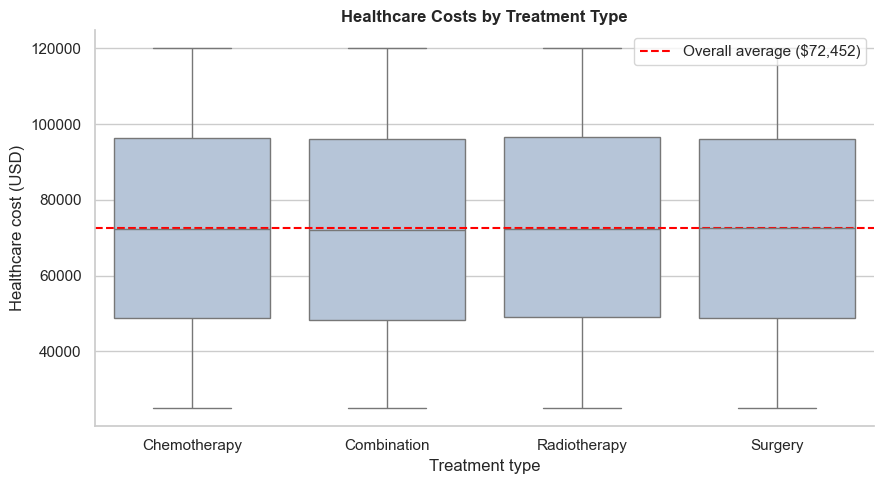

In [9]:
fig, ax = plt.subplots(figsize=(9, 5))
sns.boxplot(data=df, x="Treatment_Type", y="Healthcare_Costs", color="lightsteelblue", ax=ax)
ax.axhline(costs.mean(), color="red", linestyle="--", label=f"Overall average (${costs.mean():,.0f})")
ax.set_title("Healthcare Costs by Treatment Type", weight="bold")
ax.set_xlabel("Treatment type")
ax.set_ylabel("Healthcare cost (USD)")
ax.legend()
sns.despine()
plt.tight_layout()
plt.show()

### Conclusion

The average cost ranged from about $72,218 (combination) to $72,653 (radiotherapy), a gap of roughly $435, or 0.6%. Levene's test (p = 0.92) shows the groups have a similar spread. The ANOVA gave F = 1.372 and p = 0.249, so we fail to reject the null hypothesis. Eta-squared was 0.000025, so treatment type explains about 0.0025% of the cost differences. In this data, the type of treatment does not change what a patient costs, and the boxes in the plot look almost the same. In real life, costs usually differ a lot between treatments such as surgery and chemotherapy, which is another sign the data may be made up.

## 2.4 Conclusion 3: Correlation between the number columns

**Method: Pearson correlation tests**

- Null hypothesis: there is no linear relationship between the two columns.
- Alternative hypothesis: there is a linear relationship between the two columns.
- Significance level: 0.05, adjusted for the number of tests (explained below).

The five number columns are age, tumor size, healthcare costs, incidence rate and mortality rate. Pearson's r goes from -1 to 1, and a value near 0 means no linear relationship. We test all 10 pairs. When you run 10 tests, one of them can pass by luck, so we use the Bonferroni rule and divide 0.05 by 10, which gives 0.005.

In [10]:
number_columns = [
    "Age", "Tumor_Size_mm", "Healthcare_Costs",
    "Incidence_Rate_per_100K", "Mortality_Rate_per_100K",
]
bonferroni_alpha = 0.05 / 10

rows = []
for first, second in combinations(number_columns, 2):
    r, p = stats.pearsonr(df[first], df[second])
    rows.append({
        "Column 1": first,
        "Column 2": second,
        "r": round(r, 4),
        "p_value": round(p, 4),
        "Significant (0.05)": p < 0.05,
        "Significant (0.005)": p < bonferroni_alpha,
    })

pd.DataFrame(rows).sort_values("p_value")

,Column 1,Column 2,r,p_value,Significant (0.05),Significant (0.005)
8,Healthcare_Costs,Mortality_Rate_per_100K,-0.0050,0.0411,True,False
1,Age,Healthcare_Costs,0.0038,0.1186,False,False
7,Healthcare_Costs,Incidence_Rate_per_100K,0.0036,0.1431,False,False
0,Age,Tumor_Size_mm,-0.0032,0.1867,False,False
3,Age,Mortality_Rate_per_100K,-0.0022,0.3742,False,False
6,Tumor_Size_mm,Mortality_Rate_per_100K,0.0008,0.7471,False,False
4,Tumor_Size_mm,Healthcare_Costs,-0.0008,0.7543,False,False
9,Incidence_Rate_per_100K,Mortality_Rate_per_100K,-0.0006,0.8032,False,False
5,Tumor_Size_mm,Incidence_Rate_per_100K,-0.0005,0.8420,False,False
2,Age,Incidence_Rate_per_100K,0.0004,0.8807,False,False


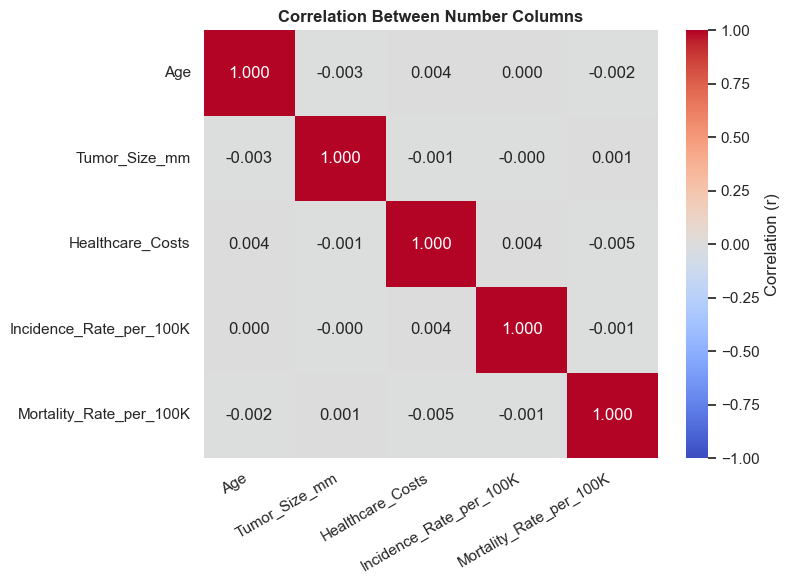

In [11]:
corr_matrix = df[number_columns].corr()

fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(corr_matrix, annot=True, fmt=".3f", cmap="coolwarm", vmin=-1, vmax=1,
            cbar_kws={"label": "Correlation (r)"}, ax=ax)
ax.set_title("Correlation Between Number Columns", weight="bold")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

### Conclusion

All 10 pairs have a correlation very close to zero. The biggest one is -0.005, between healthcare costs and mortality rate. Its p-value is 0.041, which passes 0.05 but not the stricter 0.005, so it does not count. With 167,497 rows, even a tiny correlation can pass 0.05, so the size of r matters more than the p-value. We fail to reject the null hypothesis for every pair. None of the number columns move together. In real data we would expect links such as bigger tumors costing more to treat.

## 2.5 Data limitations

All three tests found no relationship, so we checked the data for problems. The results below suggest the records may be computer generated, and that some columns should not be used as they are.

In [12]:
print("Survival_5_years vs Mortality (these should be opposites):")
display(pd.crosstab(df["Survival_5_years"], df["Mortality"]))

# A prediction that is right about half the time is no better than a coin flip.
agreement = (df["Survival_5_years"] == df["Survival_Prediction"]).mean()
print(f"Survival_Prediction matches Survival_5_years in {agreement:.1%} of rows")
print(f"Share of patients who survived: {df['Survival_5_years'].mean():.1%}\n")

# If a column is uniform, every value shows up about equally often.
for column in ["Tumor_Size_mm", "Incidence_Rate_per_100K", "Mortality_Rate_per_100K"]:
    p_value = stats.chisquare(df[column].value_counts()).pvalue
    print(f"{column}: uniform test p-value = {p_value:.3f}")

Survival_5_years vs Mortality (these should be opposites):


Mortality,0,1
Survival_5_years,,
0,40347,26763
1,60007,40380


Survival_Prediction matches Survival_5_years in 52.2% of rows
Share of patients who survived: 59.9%

Tumor_Size_mm: uniform test p-value = 0.773
Incidence_Rate_per_100K: uniform test p-value = 0.784
Mortality_Rate_per_100K: uniform test p-value = 0.356


- `Survival_5_years` and `Mortality` disagree for about half of the patients, so we only use `Survival_5_years` as the outcome.
- `Survival_Prediction` matches the real outcome in about 52% of rows. That is no better than guessing, so we do not use it.
- Tumor size and the two rate columns look evenly spread (p above 0.05). Real medical measurements rarely look like that.
- The rate columns change from row to row inside one country, so they are not real country-level rates.
- About 60% of patients survived, so any model we build later has to beat 60% to be useful.